# 03 - Comparaison des modèles

Ce notebook rassemble les résultats obtenus sur l'ensemble de test : U-Net 2D de référence,
Wavelet-Guided U-Net (fusion en entrée et injection multi-échelle) et, lorsqu'il a été entraîné,
U-Net 3D. Toutes les valeurs sont lues dans les fichiers produits par `scripts/evaluate.py` et
`scripts/analyze_results.py` ; rien n'est saisi à la main.

L'ensemble de test (20 volumes) n'a servi ni à l'entraînement ni au choix des modèles, qui a été fait
sur la validation.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.visualization.plots import MODEL_LABELS
df = pd.read_csv("results/metrics/test_per_volume.csv")
vessel = df[df["class"] == "vessel"]
print(df.groupby(["model"])["seed"].unique().to_dict())
print("volumes de test :", df["case_id"].nunique(), "| conditions :", list(df["condition"].unique()))

{'unet2d': array([0, 1]), 'unet3d': array([0]), 'wavelet_unet_dwt_haar_ms': array([0, 1]), 'wavelet_unet_swt_haar': array([0, 1])}
volumes de test : 20 | conditions : ['original', 'blur_1mm', 'down_x2', 'down_x4', 'down_x2_noise20']


## 1. Entraînement

Résumé de chaque entraînement : meilleure époque (sélectionnée sur le Dice des vaisseaux en
validation), nombre d'époques effectuées et durée sur CPU.

In [2]:
rows = []
for run in sorted(Path("experiments").glob("*_seed*")):
    if (run / "summary.json").exists():
        s = json.loads((run / "summary.json").read_text())
        rows.append({"run": run.name, **{k: s[k] for k in ("best_epoch", "epochs_run", "best_val_dice_vessel", "total_time_min", "parameters")}})
pd.DataFrame(rows).round(4)

,run,best_epoch,epochs_run,best_val_dice_vessel,total_time_min,parameters
0,unet2d_seed0,12,19,0.5311,106.0307,1942323
1,unet2d_seed1,18,25,0.4755,246.3124,1942323
2,unet3d_seed0,32,40,0.4424,329.9796,600680
3,wavelet_unet_dwt_haar_ms_seed0,10,17,0.5125,170.1685,1945779
4,wavelet_unet_dwt_haar_ms_seed1,17,24,0.5010,151.9472,1945779
5,wavelet_unet_swt_haar_seed0,12,19,0.5157,108.5163,1942899
6,wavelet_unet_swt_haar_seed1,22,25,0.5002,1043.6340,1942899


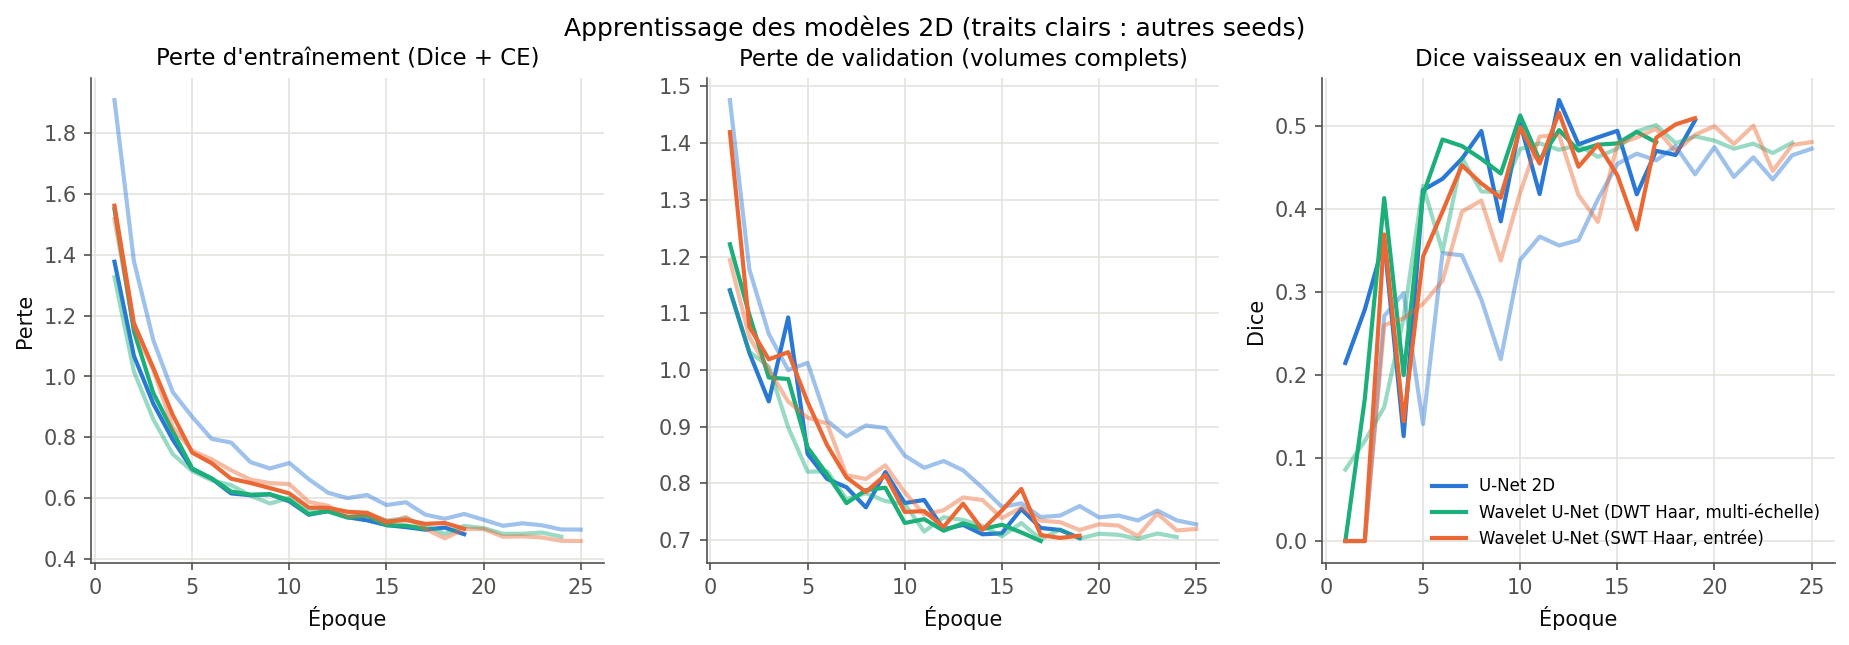

In [3]:
display(Image("results/figures/training/courbes_apprentissage.png"))

Les trois modèles 2D convergent de façon très semblable : les courbes de perte se superposent et le Dice de validation plafonne vers 0,47-0,53 pour toutes les seeds. Plusieurs entraînements, y compris le U-Net standard (seed 1), ne prédisent aucun vaisseau pendant les deux premières époques, ce qui justifie le minimum de 12 époques avant l'arrêt anticipé. Le Dice de validation varie beaucoup d'une époque à l'autre (8 volumes, une coupe sur trois) : la sélection du meilleur modèle reste bruitée. Les durées affichées incluent des mises en veille de la machine pour certains entraînements ; la durée médiane d'une époque (environ 5,5 min avec deux entraînements en parallèle, 9,5 min pour la variante SWT seed 1 entraînée en partie sur batterie) est plus représentative.

## 2. Résultats par volume sur les images originales

Les métriques sont calculées par volume puis résumées (moyenne, écart-type, médiane). Lorsque
plusieurs seeds sont disponibles, les valeurs par volume sont d'abord moyennées sur les seeds.

In [4]:
orig = vessel[vessel["condition"] == "original"]
cols = ["dice", "iou", "precision", "recall", "f1", "hd95_mm", "cldice"]
orig.groupby(["model", "seed"])[cols].mean().round(4)

dice     iou  precision  recall      f1  hd95_mm  cldice
model                    seed                                                            
unet2d                   0     0.5446  0.3818     0.6612  0.5265  0.5446  35.1518  0.6040
                         1     0.4931  0.3364     0.5542  0.5519  0.4931  54.4599  0.5531
unet3d                   0     0.4407  0.2940     0.4754  0.4876  0.4407  77.9555  0.4903
wavelet_unet_dwt_haar_ms 0     0.5292  0.3725     0.6909  0.5187  0.5292  26.9560  0.6128
                         1     0.5640  0.3979     0.5712  0.6346  0.5640  33.8431  0.6233
wavelet_unet_swt_haar    0     0.5267  0.3673     0.6309  0.5415  0.5267  34.8927  0.5913
                         1     0.5513  0.3908     0.6092  0.5903  0.5513  47.5913  0.6050

In [5]:
per_model = orig.groupby(["model", "case_id"])[cols].mean().groupby("model").agg(["mean", "std", "median"])
per_model.round(4).T

model              unet2d   unet3d  wavelet_unet_dwt_haar_ms  wavelet_unet_swt_haar
dice      mean     0.5188   0.4407                    0.5466                 0.5390
          std      0.1162   0.1516                    0.1142                 0.1273
          median   0.5301   0.4742                    0.5566                 0.5646
iou       mean     0.3591   0.2940                    0.3852                 0.3790
          std      0.1038   0.1237                    0.1053                 0.1165
          median   0.3618   0.3109                    0.3860                 0.3943
precision mean     0.6077   0.4754                    0.6311                 0.6201
          std      0.1611   0.1600                    0.1614                 0.1659
          median   0.5854   0.4906                    0.6434                 0.6156
recall    mean     0.5392   0.4876                    0.5767                 0.5659
          std      0.2137   0.2284                    0.2118                 0.2213
          median   0.5307   0.4928                    0.5985                 0.5660
f1        mean     0.5188   0.4407                    0.5466                 0.5390
          std      0.1162   0.1516                    0.1142                 0.1273
          median   0.5301   0.4742                    0.5566                 0.5646
hd95_mm   mean    44.8058  77.9555                   30.3995                41.2420
          std     17.0768  23.4795                   14.1137                19.8164
          median  46.0019  79.0514                   25.8070                37.0643
cldice    mean     0.5785   0.4903                    0.6181                 0.5982
          std      0.1110   0.1458                    0.1138                 0.1139
          median   0.5961   0.4724                    0.6493                 0.6243

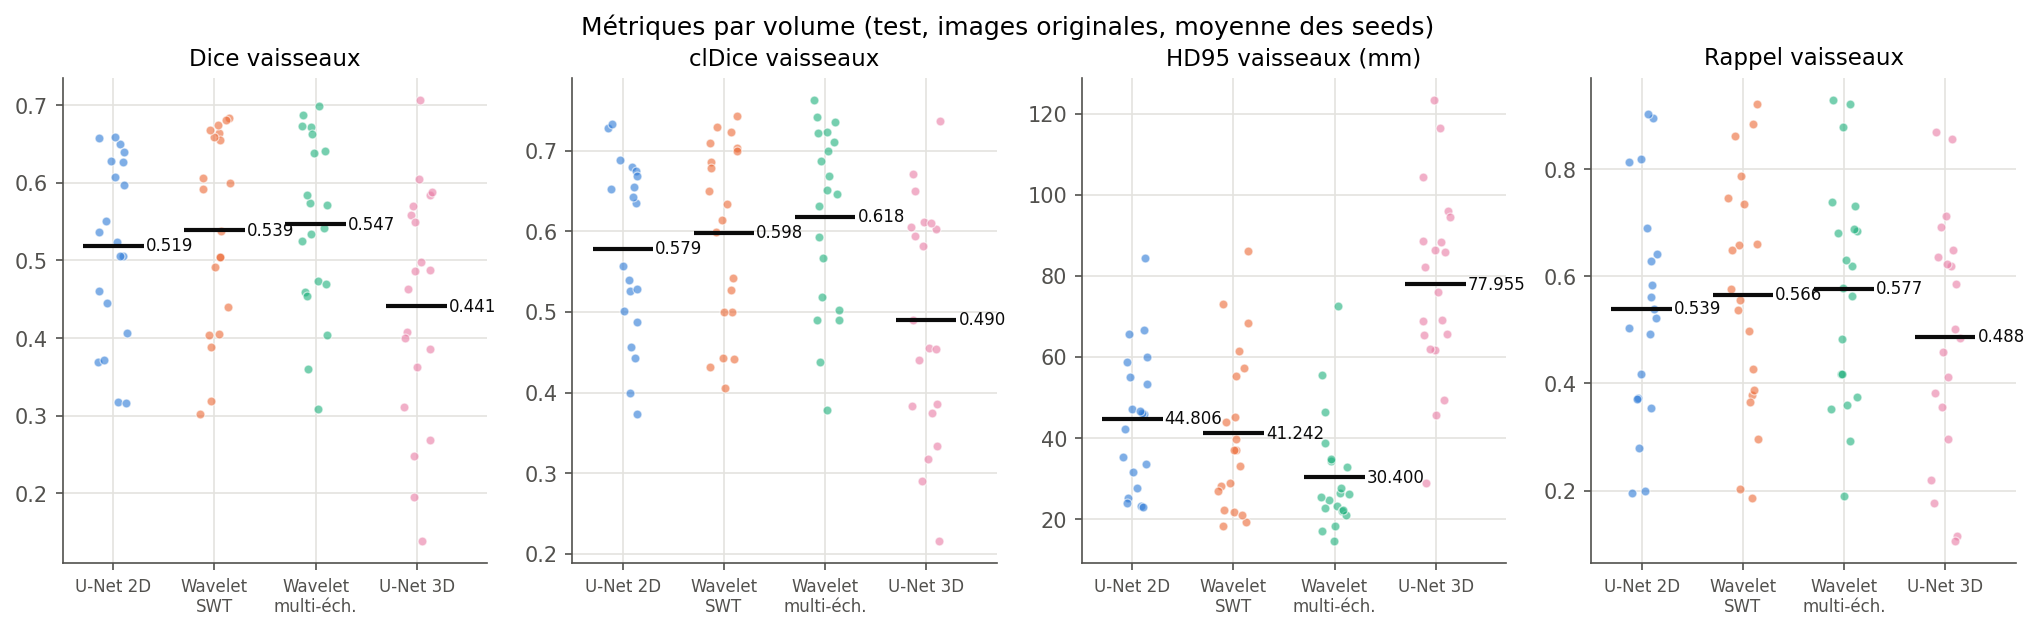

In [6]:
display(Image("results/figures/comparison/metriques_par_modele.png"))

Test de Wilcoxon apparié sur les volumes (différence = modèle - U-Net 2D) :

In [7]:
tests = pd.read_csv("results/metrics/test_wilcoxon_vs_unet2d.csv")
tests[tests["condition"] == "original"].round(4)

,seeds,condition,model,metric,n_volumes,mean_diff_vs_unet2d,median_diff_vs_unet2d,volumes_better,volumes_worse,wilcoxon_p
0,seed 0,original,wavelet_unet_swt_haar,dice,20,-0.0179,-0.0151,8,12,0.0696
1,seed 0,original,wavelet_unet_swt_haar,cldice,20,-0.0127,-0.0096,8,12,0.2162
2,seed 0,original,wavelet_unet_swt_haar,hd95_mm,20,-0.2592,2.4360,9,11,0.9273
3,seed 0,original,wavelet_unet_swt_haar,recall,20,0.0150,0.0193,13,7,0.5459
4,seed 0,original,wavelet_unet_swt_haar,precision,20,-0.0302,-0.0269,6,14,0.1536
5,seed 0,original,wavelet_unet_dwt_haar_ms,dice,20,-0.0153,0.0048,11,9,0.5958
6,seed 0,original,wavelet_unet_dwt_haar_ms,cldice,20,0.0088,0.0289,14,6,0.2774
7,seed 0,original,wavelet_unet_dwt_haar_ms,hd95_mm,20,-8.1959,-8.2750,14,6,0.0266
8,seed 0,original,wavelet_unet_dwt_haar_ms,recall,20,-0.0078,0.0242,12,8,0.9273
9,seed 0,original,wavelet_unet_dwt_haar_ms,precision,20,0.0297,0.0301,12,8,0.5459


In [8]:
seed_spread = pd.read_csv("results/metrics/test_seed_spread.csv")
seed_spread[(seed_spread["class"] == "vessel") & (seed_spread["condition"] == "original")].round(4)

,class,model,condition,dice_mean,dice_std,dice_count,cldice_mean,cldice_std,cldice_count,hd95_mm_mean,hd95_mm_std,hd95_mm_count
22,vessel,unet2d,original,0.5188,0.0364,2,0.5785,0.0360,2,44.8058,13.6528,2
25,vessel,unet3d,original,0.4407,NaN,1,0.4903,NaN,1,77.9555,NaN,1
30,vessel,wavelet_unet_dwt_haar_ms,original,0.5466,0.0246,2,0.6181,0.0074,2,30.3995,4.8700,2
35,vessel,wavelet_unet_swt_haar,original,0.5390,0.0174,2,0.5982,0.0097,2,41.2420,8.9793,2


Sur les images originales, la conclusion dépend de la seed :

- seed 0 : le U-Net 2D obtient le meilleur Dice (0,545 contre 0,527 pour la variante SWT et 0,529 pour la variante multi-échelle), sans différence significative (p = 0,07 et 0,60) ;
- seed 1 : le U-Net est nettement moins bon (Dice 0,493, précision 0,554) et les deux variantes ondelettes le dépassent sur 17 à 18 volumes sur 20 (0,551 et 0,564).

L'écart entre les deux entraînements du U-Net (0,052 de Dice) est plus grand que les écarts entre modèles (environ 0,02 en moyenne des seeds). Les tests de Wilcoxon sur les volumes ne prennent en compte que la variabilité entre volumes : ils peuvent être significatifs pour une seed et dans le sens inverse pour l'autre. Avec deux seeds, je ne peux donc pas conclure que les ondelettes améliorent le Dice ou le clDice.

Le seul effet de même sens pour les deux seeds concerne la distance de surface : la variante multi-échelle a un HD95 plus faible que le U-Net (- 8,2 mm pour la seed 0, p = 0,03 ; - 20,6 mm pour la seed 1, p = 0,0003), avec moins de composantes isolées sans recouvrement avec la référence (59 contre 86, et 104 contre 121 par volume). Elle produit donc moins de faux positifs éloignés des vaisseaux annotés. Cet effet reste à confirmer avec plus d'entraînements. Le U-Net 3D, entraîné une seule fois et dans un budget de calcul limité, est nettement en dessous des modèles 2D (Dice 0,441, HD95 78 mm), avec beaucoup de petites composantes isolées.

## 3. Structures fines, continuité et composantes

In [9]:
bins = [c for c in df.columns if c.startswith("cl_recall_")]
comp = ["gt_components", "pred_components", "gt_components_detected", "pred_components_fp", "largest_component_fraction"]
orig.groupby(["model", "case_id"])[bins + comp].mean().groupby("model").mean().round(3).T

model,unet2d,unet3d,wavelet_unet_dwt_haar_ms,wavelet_unet_swt_haar
cl_recall_r0-1.5mm,0.459,0.427,0.506,0.471
cl_recall_r1.5-3mm,0.742,0.719,0.776,0.764
cl_recall_r>3mm,0.670,0.660,0.702,0.695
gt_components,49.000,49.000,49.000,49.000
pred_components,145.150,227.050,114.250,124.575
gt_components_detected,0.457,0.440,0.507,0.453
pred_components_fp,103.050,186.200,81.125,85.775
largest_component_fraction,0.459,0.318,0.484,0.425


comparaison_best_hepaticvessel_314.png


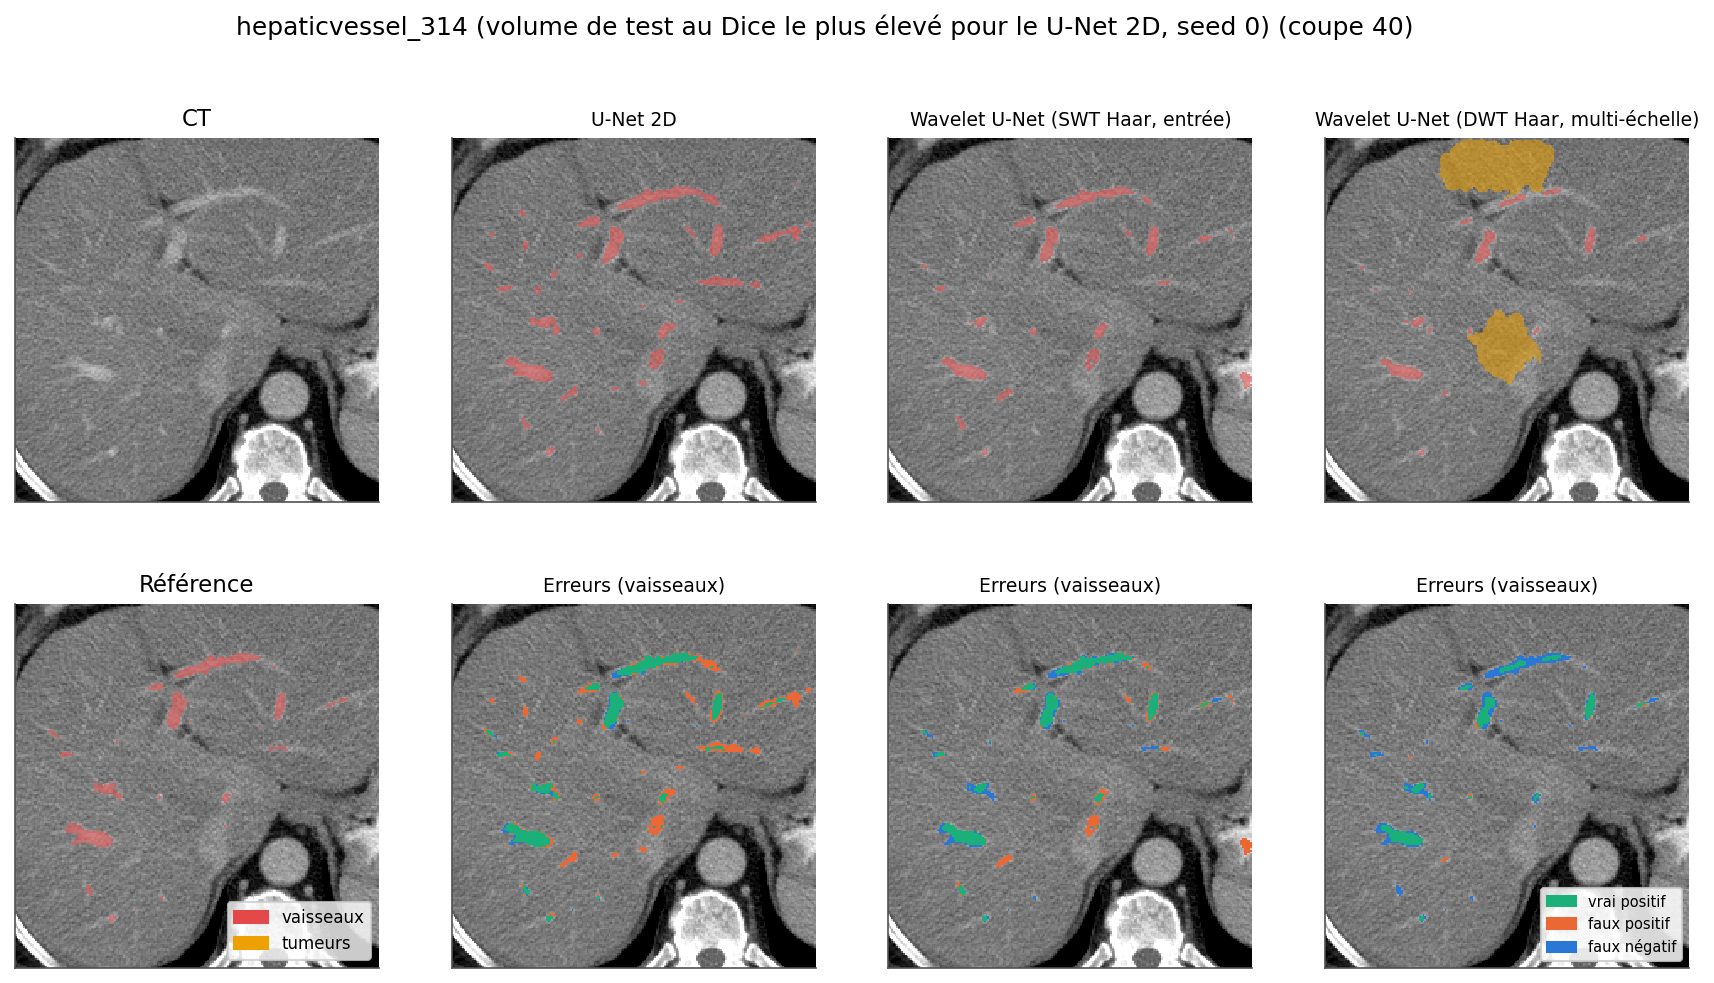

comparaison_median_hepaticvessel_199.png


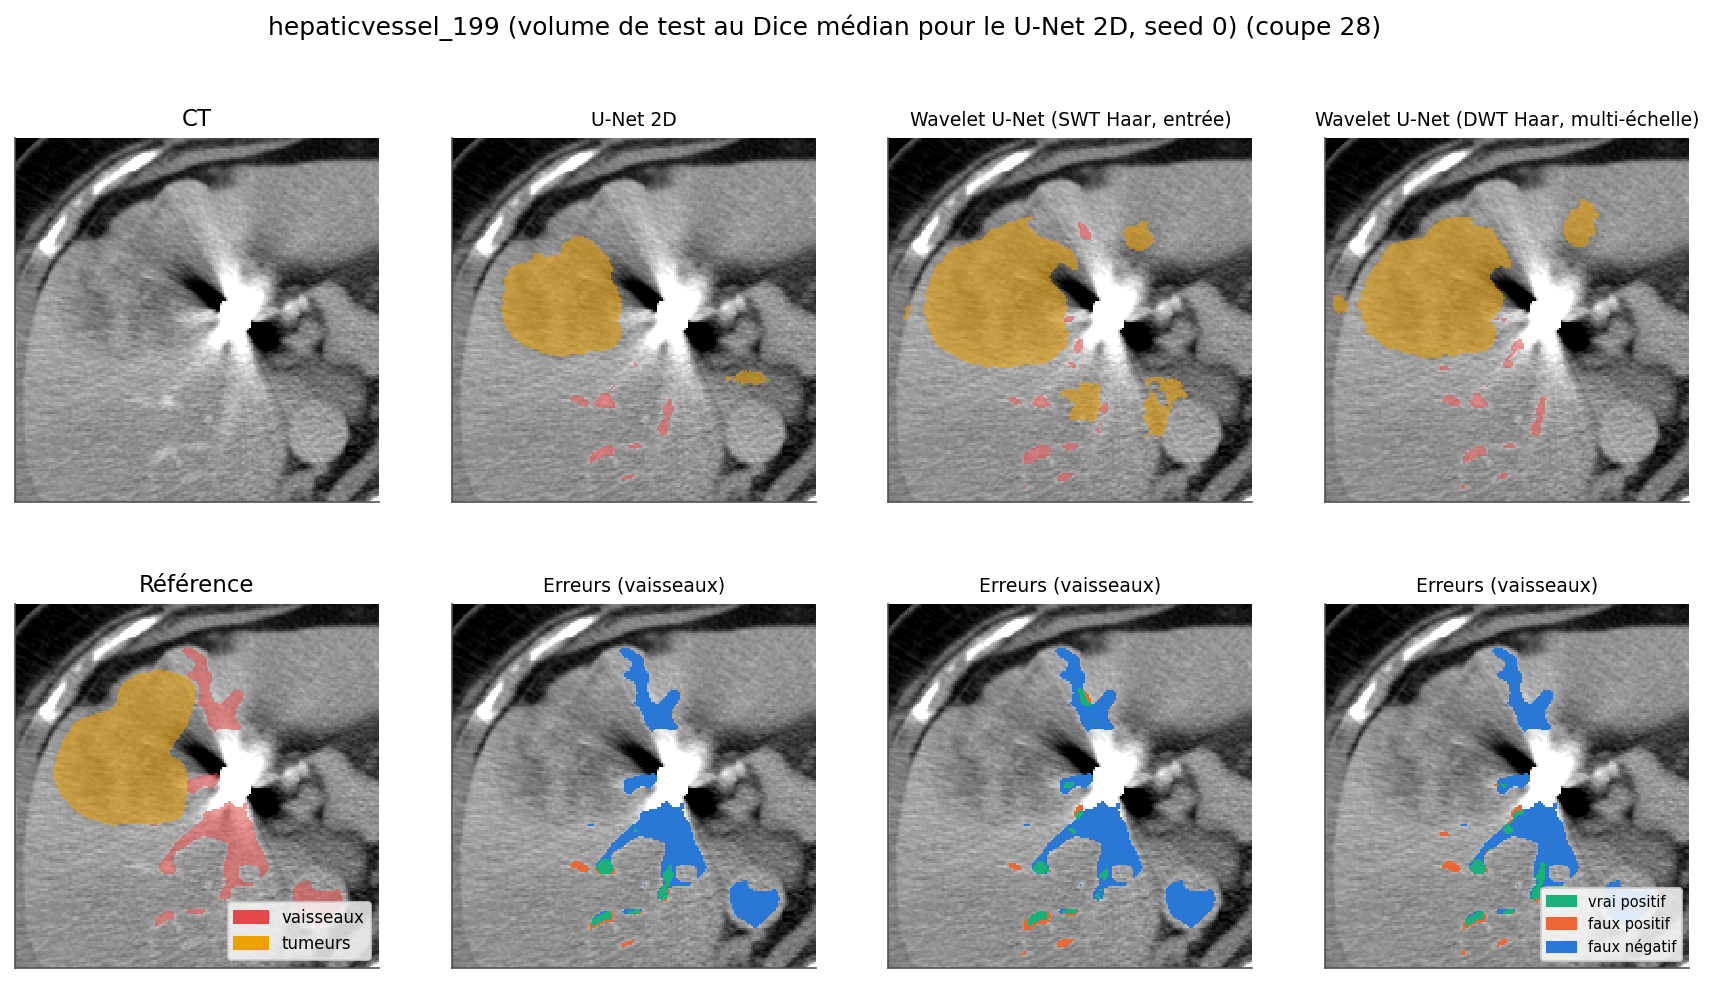

comparaison_worst_hepaticvessel_068.png


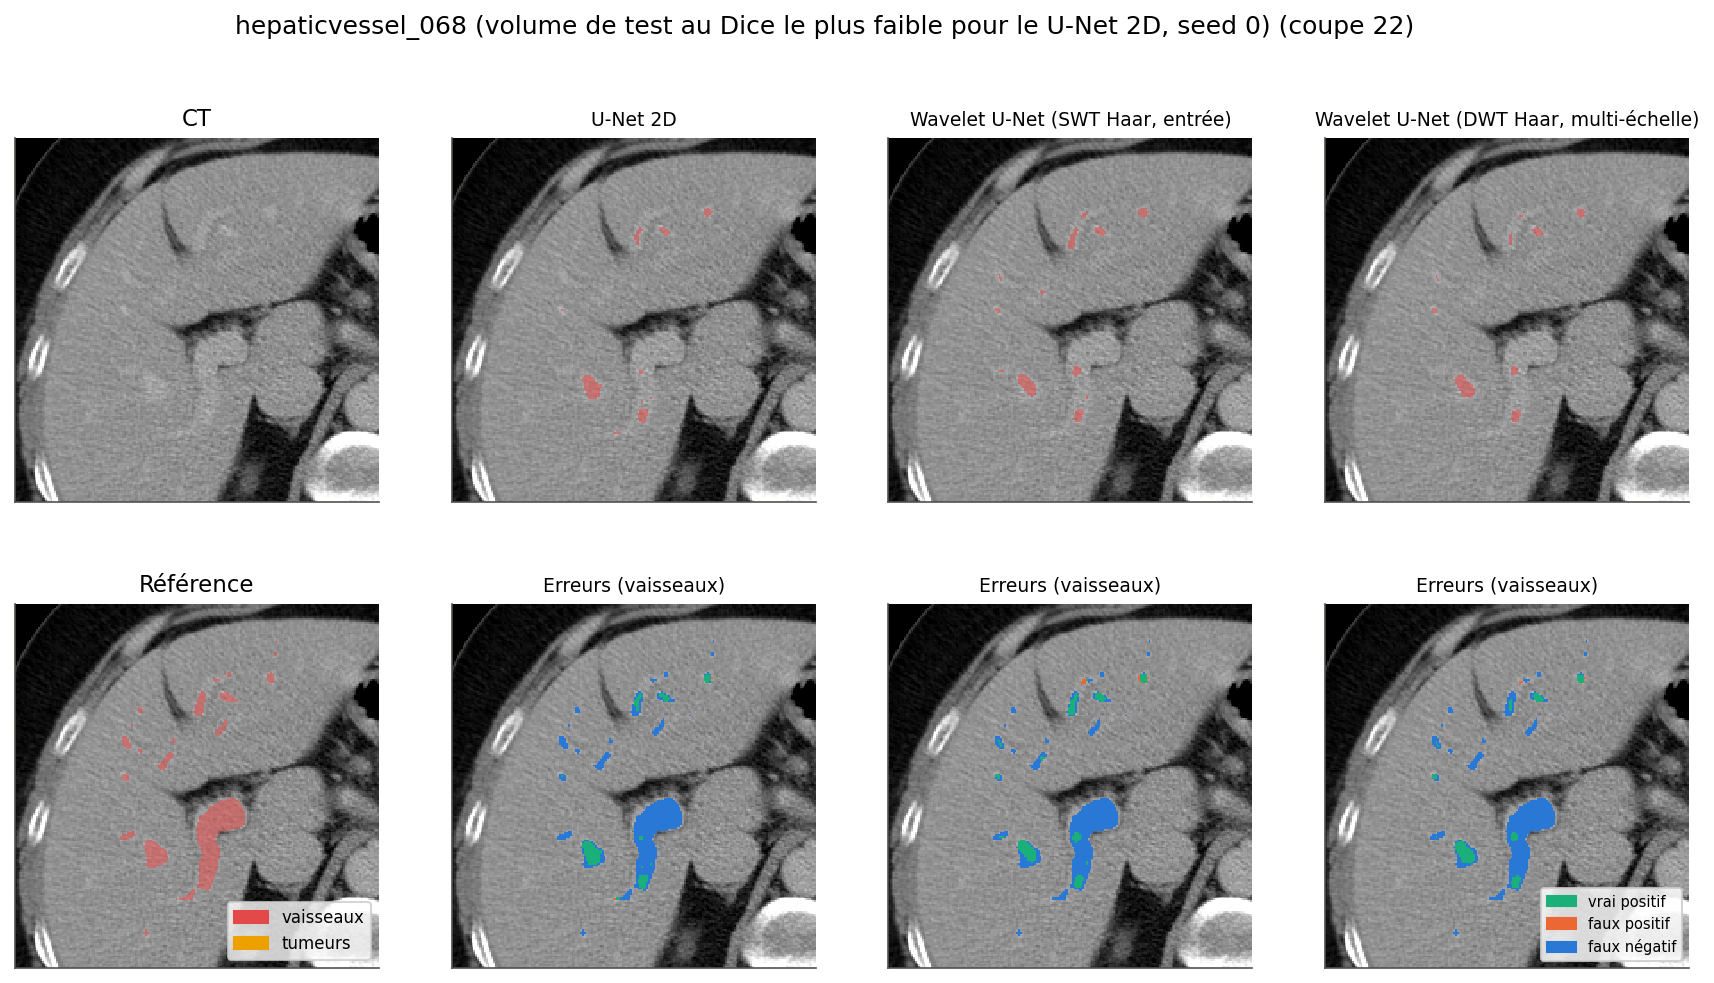

In [10]:
for path in sorted(Path("results/figures/predictions").glob("comparaison_*.png")):
    print(path.name); display(Image(str(path)))

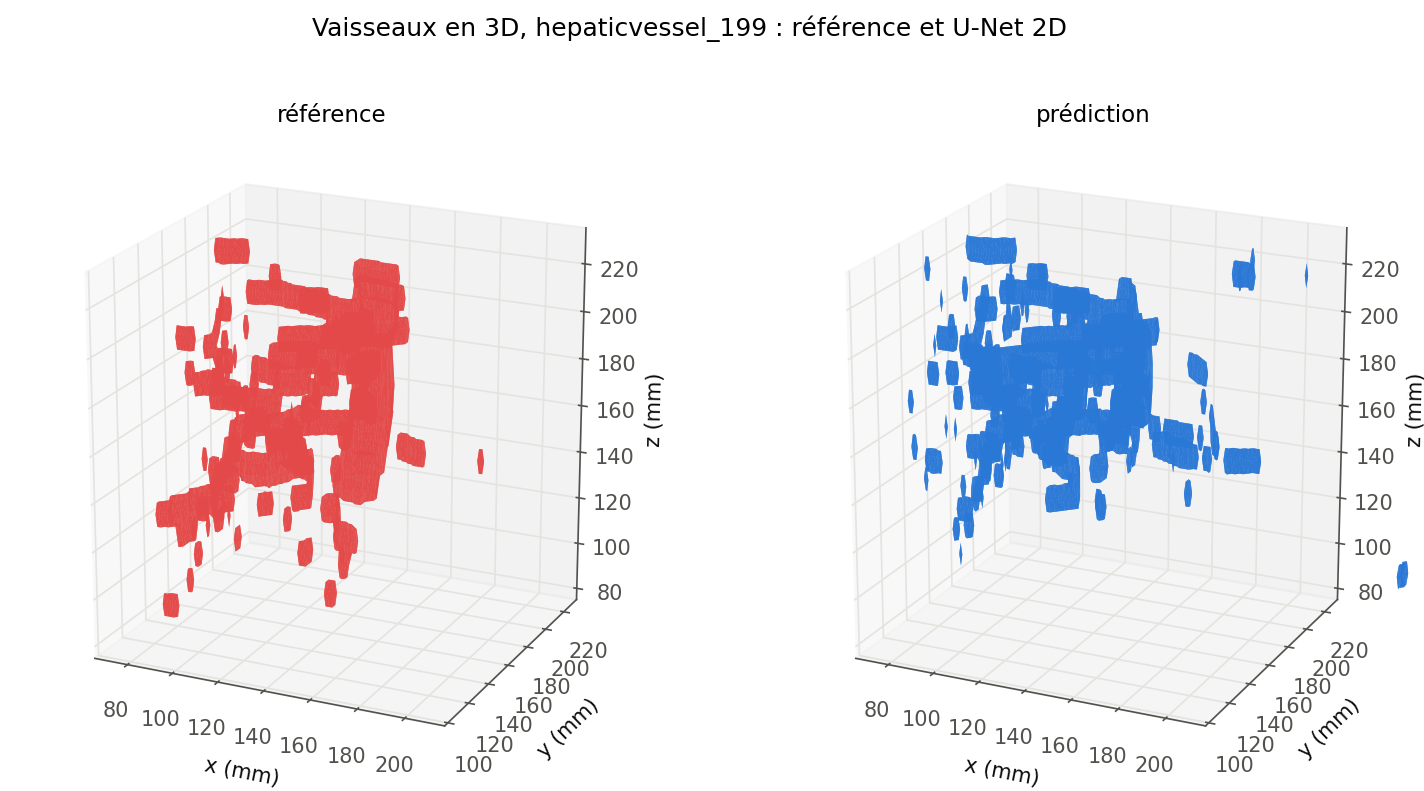

In [11]:
for path in sorted(Path("results/figures/predictions").glob("rendu3d_*.png")):
    display(Image(str(path)))

Pour tous les modèles, les petits vaisseaux sont beaucoup moins bien retrouvés : sur les images originales, le rappel de la ligne centrale est de 0,43 à 0,57 pour un rayon local inférieur à 1,5 mm, contre 0,72 à 0,82 entre 1,5 et 3 mm et 0,65 à 0,74 au-delà. Les différences entre modèles sur les petits vaisseaux suivent les mêmes variations entre seeds que le Dice et ne sont pas systématiques. Seule une partie des composantes connexes de référence est touchée par les prédictions (42 à 56 %), alors que chaque prédiction contient de 59 à 186 composantes sans recouvrement : la segmentation est fragmentée, ce qui est attendu avec des coupes de 5 mm traitées indépendamment. Les figures montrent aussi des erreurs dans les zones d'artefacts métalliques et des gros troncs peu contrastés manqués (cas au Dice le plus faible).

## 4. Robustesse à la dégradation de la résolution

Les images de test sont floutées ou sous-échantillonnées dans le plan puis ramenées à la grille
d'origine ; le masque de référence n'est pas modifié. Ces images simulées ne sont pas des
acquisitions réelles.

In [12]:
table = vessel.groupby(["model", "case_id", "condition"])[["dice", "cldice", "hd95_mm"] + bins].mean()
table = table.groupby(["model", "condition"]).mean().round(4)
order = ["original", "blur_1mm", "down_x2", "down_x3", "down_x4", "down_x2_noise20"]
table.reset_index().assign(condition=lambda d: pd.Categorical(d["condition"], order, ordered=True)).sort_values(["model", "condition"])

,model,condition,dice,cldice,hd95_mm,cl_recall_r0-1.5mm,cl_recall_r1.5-3mm,cl_recall_r>3mm
4,unet2d,original,0.5188,0.5785,44.8058,0.4589,0.7416,0.6697
0,unet2d,blur_1mm,0.5587,0.6234,26.3083,0.4176,0.7625,0.7003
1,unet2d,down_x2,0.5291,0.5972,38.7845,0.4828,0.7646,0.6823
3,unet2d,down_x4,0.4863,0.5396,43.2952,0.3199,0.6941,0.7030
2,unet2d,down_x2_noise20,0.4611,0.4948,50.6791,0.3241,0.6249,0.6154
7,unet3d,original,0.4407,0.4903,77.9555,0.4267,0.7192,0.6602
5,unet3d,down_x2,0.4264,0.4569,89.3376,0.4242,0.7415,0.6956
6,unet3d,down_x4,0.3408,0.3479,106.1930,0.2748,0.6701,0.7224
12,wavelet_unet_dwt_haar_ms,original,0.5466,0.6181,30.3995,0.5064,0.7759,0.7020
8,wavelet_unet_dwt_haar_ms,blur_1mm,0.5092,0.5973,27.5874,0.3702,0.6976,0.6508


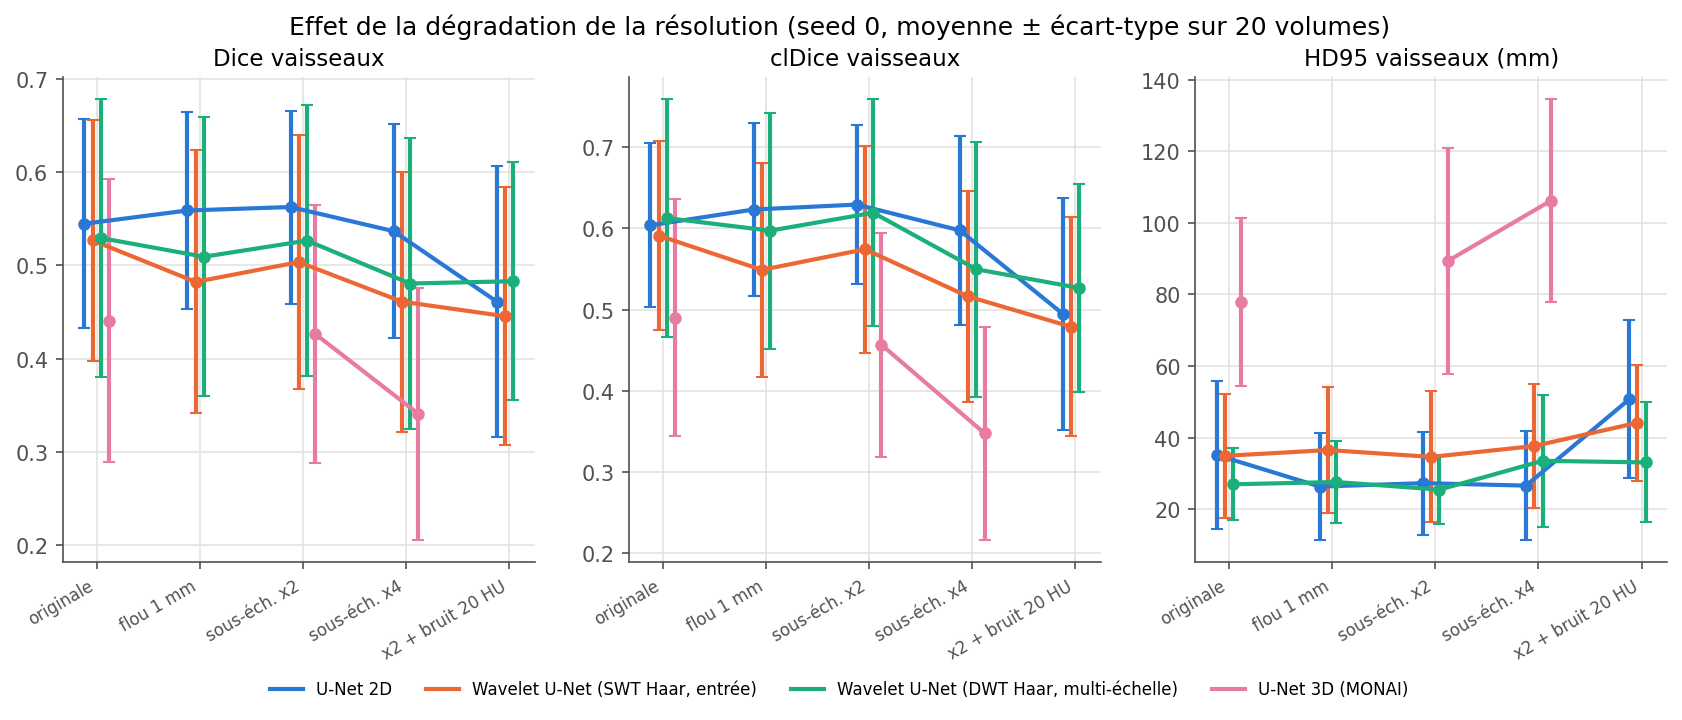

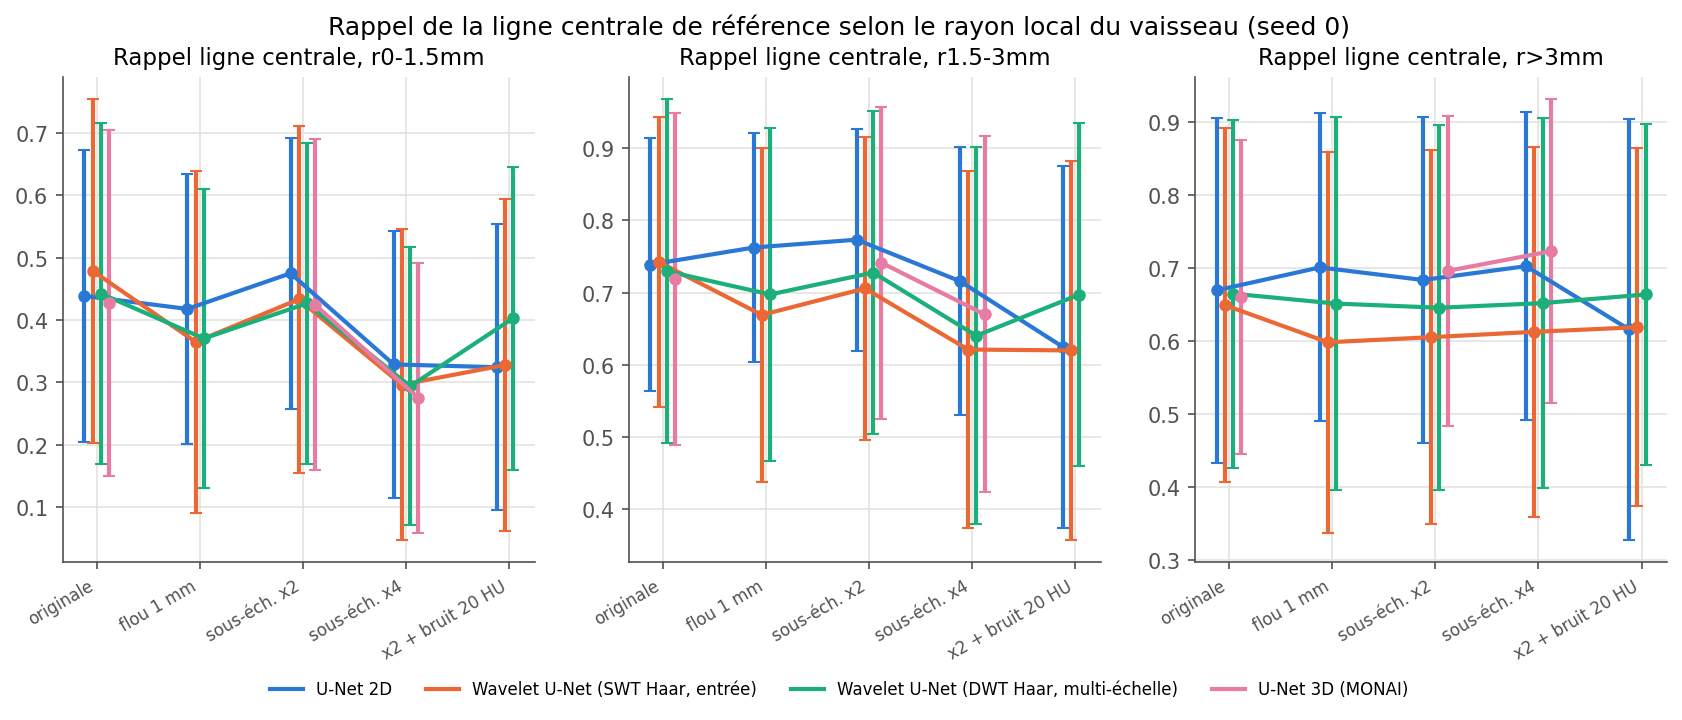

In [13]:
display(Image("results/figures/resolution/metriques_selon_resolution.png"))
display(Image("results/figures/resolution/rappel_par_calibre.png"))

In [14]:
tests[(tests["condition"] != "original") & tests["metric"].isin(["dice", "cldice"])].round(4)

,seeds,condition,model,metric,n_volumes,mean_diff_vs_unet2d,median_diff_vs_unet2d,volumes_better,volumes_worse,wilcoxon_p
15,seed 0,blur_1mm,wavelet_unet_swt_haar,dice,20,-0.0765,-0.0781,3,17,0.0003
16,seed 0,blur_1mm,wavelet_unet_swt_haar,cldice,20,-0.0743,-0.0824,3,17,0.0009
20,seed 0,blur_1mm,wavelet_unet_dwt_haar_ms,dice,20,-0.0496,-0.0277,6,14,0.0192
21,seed 0,blur_1mm,wavelet_unet_dwt_haar_ms,cldice,20,-0.0260,-0.0001,10,10,0.3683
25,seed 0,down_x2,wavelet_unet_swt_haar,dice,20,-0.0590,-0.0544,3,17,0.0000
26,seed 0,down_x2,wavelet_unet_swt_haar,cldice,20,-0.0550,-0.0629,5,15,0.0003
30,seed 0,down_x2,wavelet_unet_dwt_haar_ms,dice,20,-0.0360,-0.0190,8,12,0.0696
31,seed 0,down_x2,wavelet_unet_dwt_haar_ms,cldice,20,-0.0100,0.0152,13,7,0.7285
35,seed 0,down_x2,unet3d,dice,20,-0.1360,-0.1336,1,19,0.0000
36,seed 0,down_x2,unet3d,cldice,20,-0.1725,-0.1762,0,20,0.0000


predictions_blur_1mm_hepaticvessel_199.png


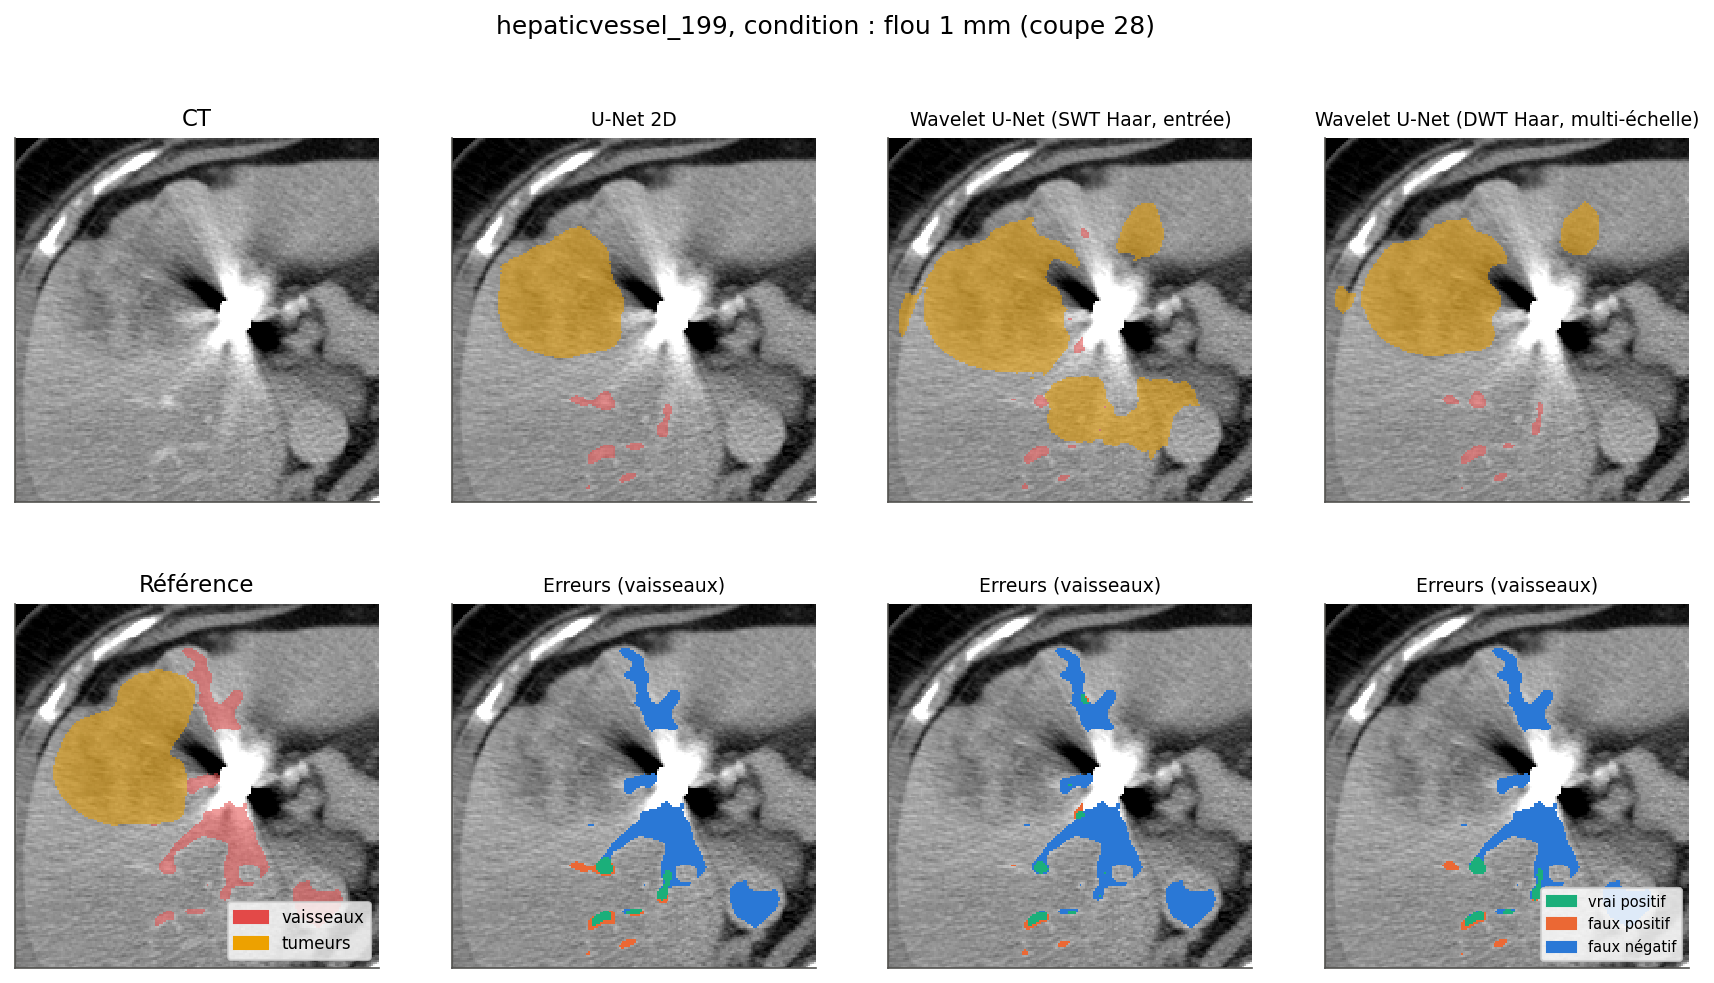

predictions_down_x2_hepaticvessel_199.png


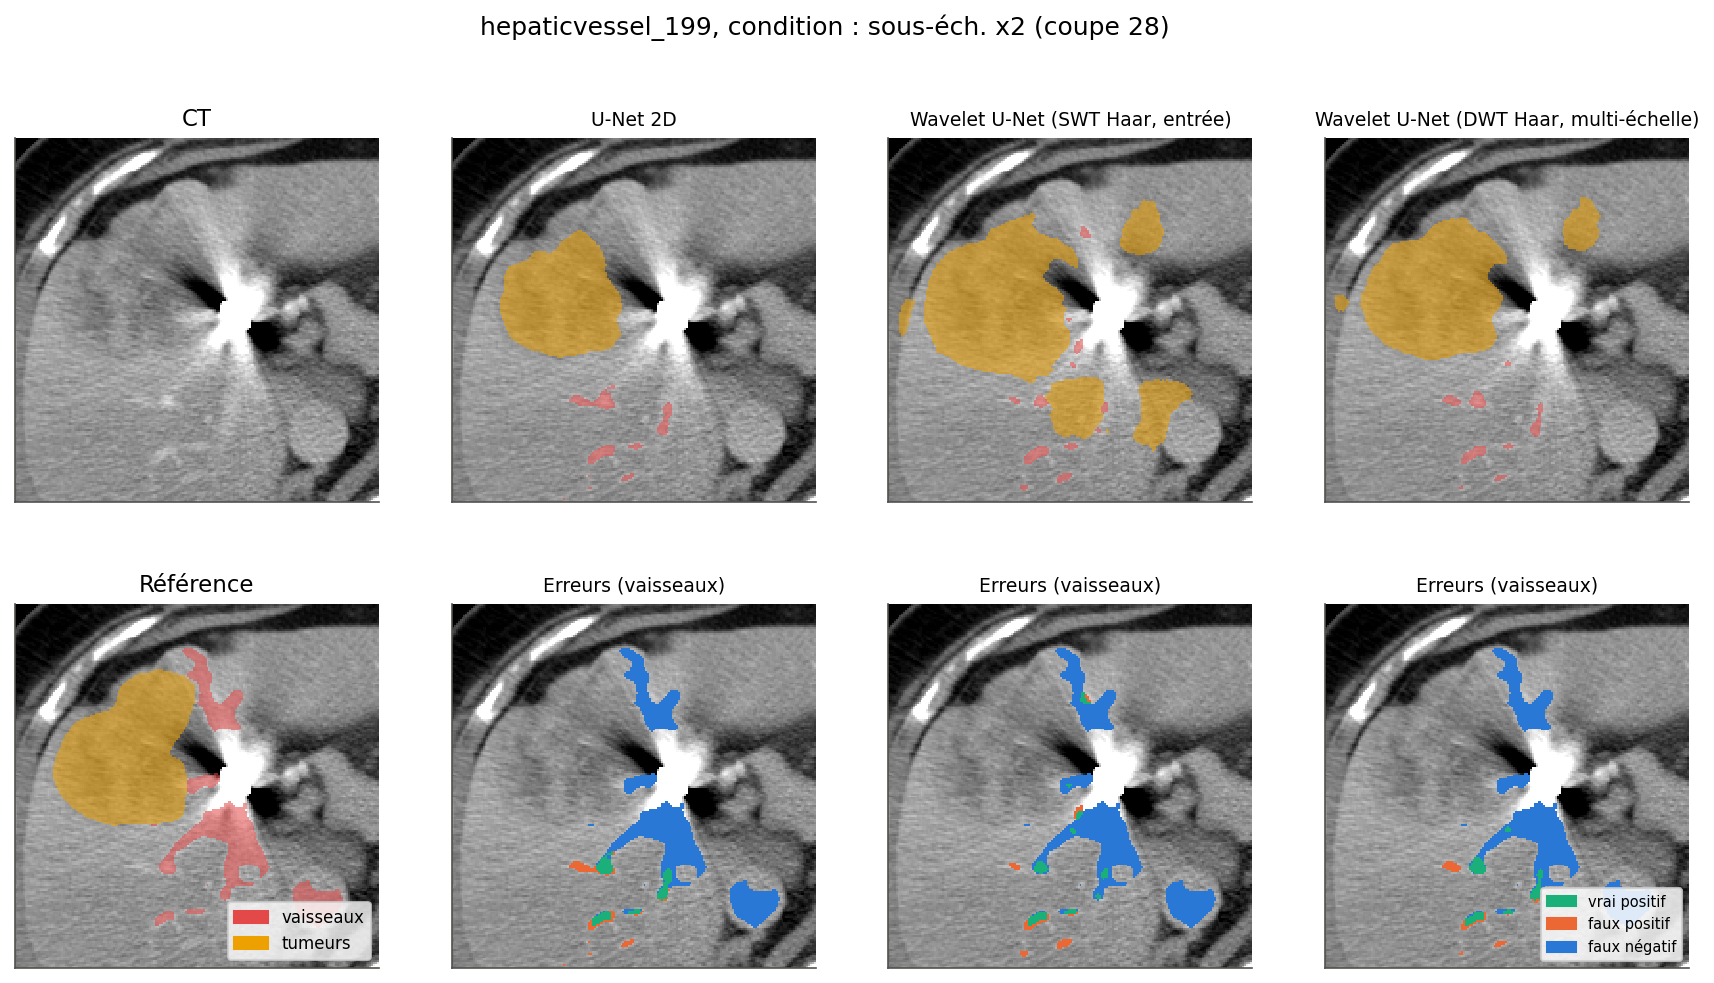

predictions_down_x2_noise20_hepaticvessel_199.png


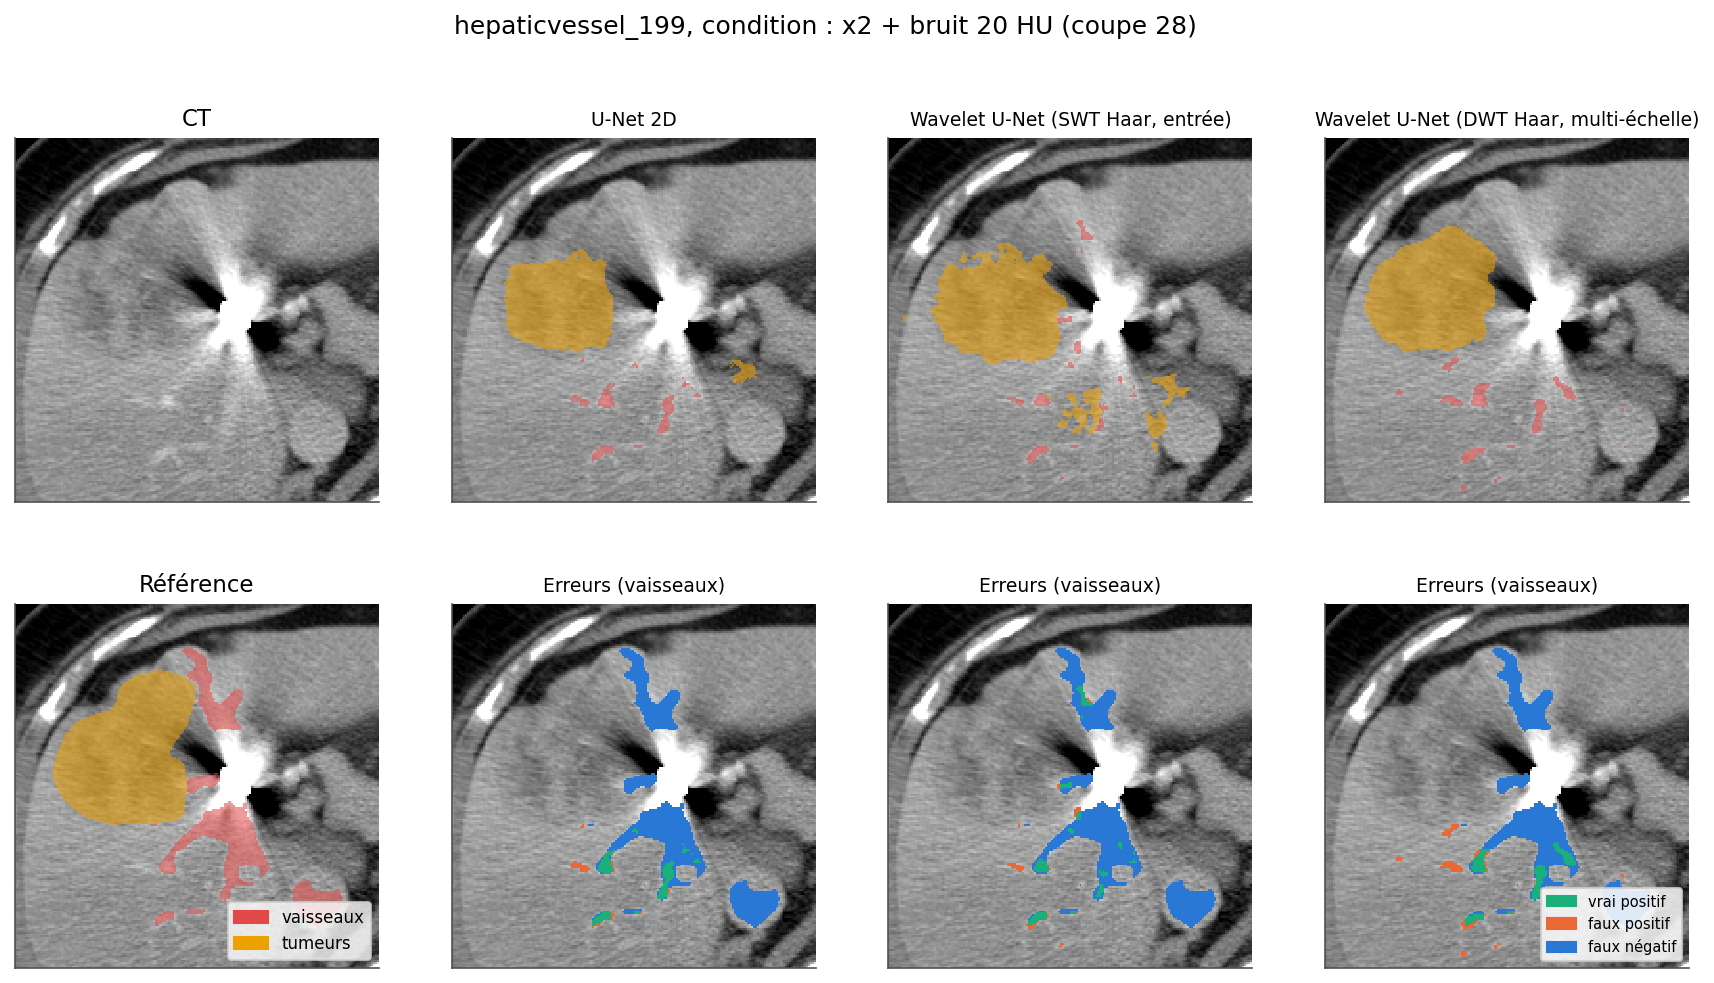

predictions_down_x4_hepaticvessel_199.png


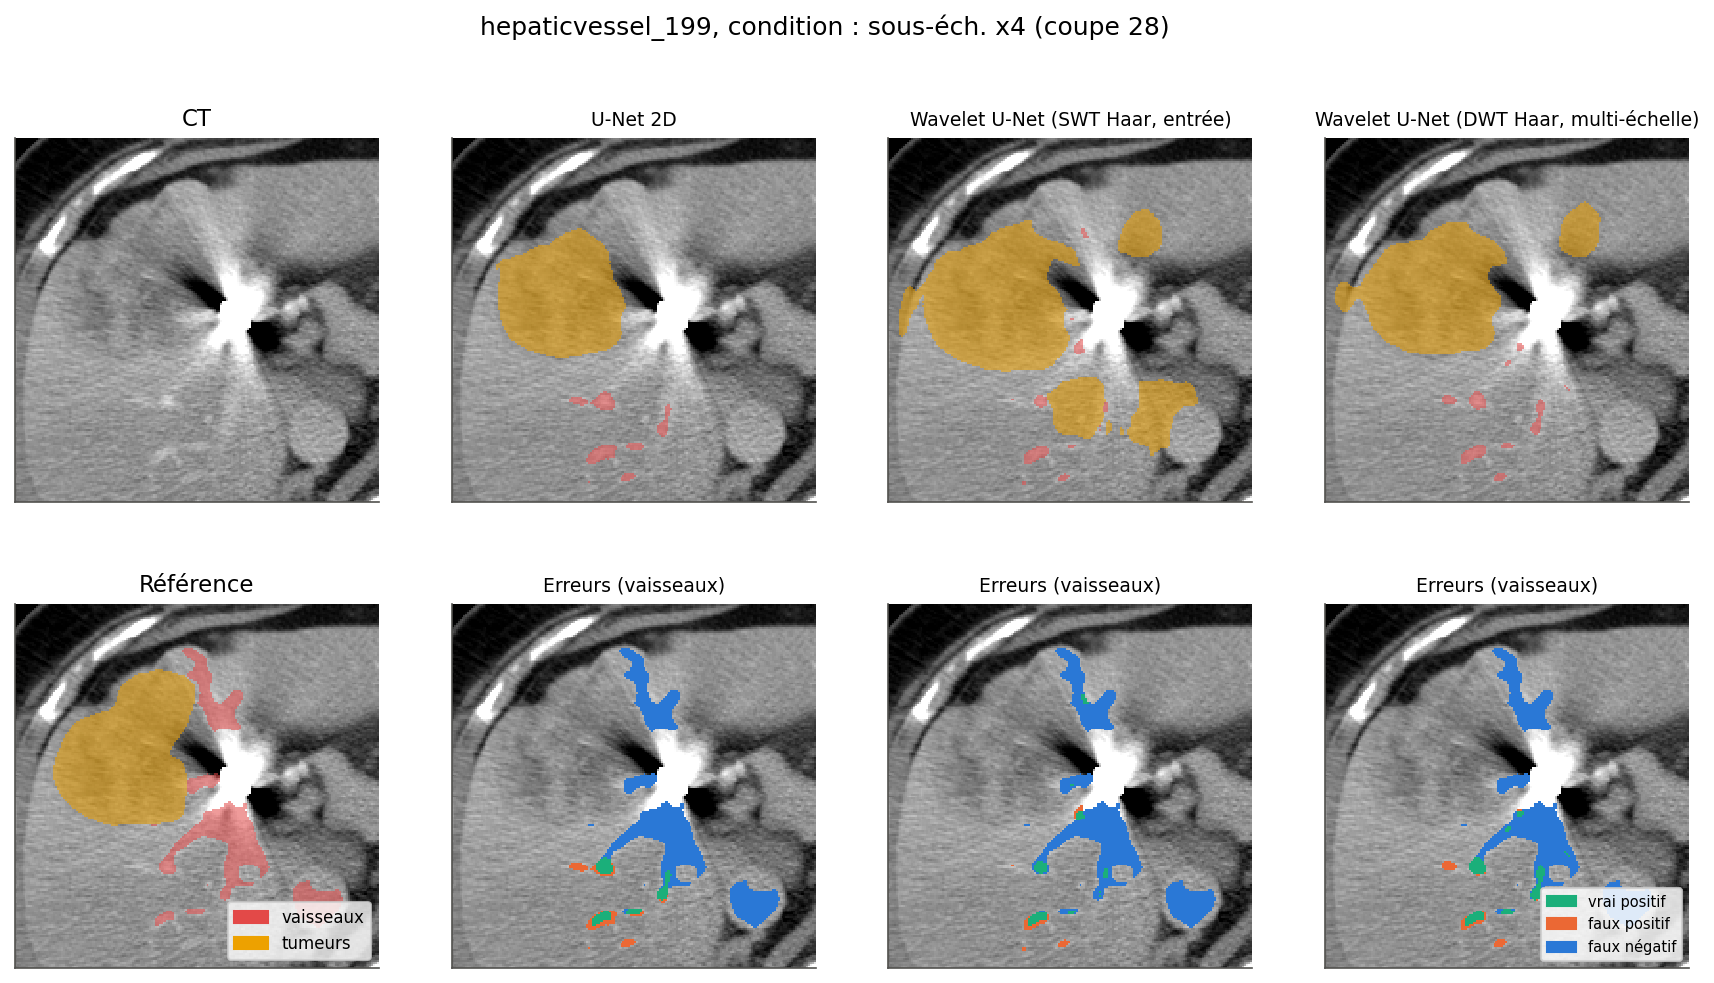

predictions_original_hepaticvessel_199.png


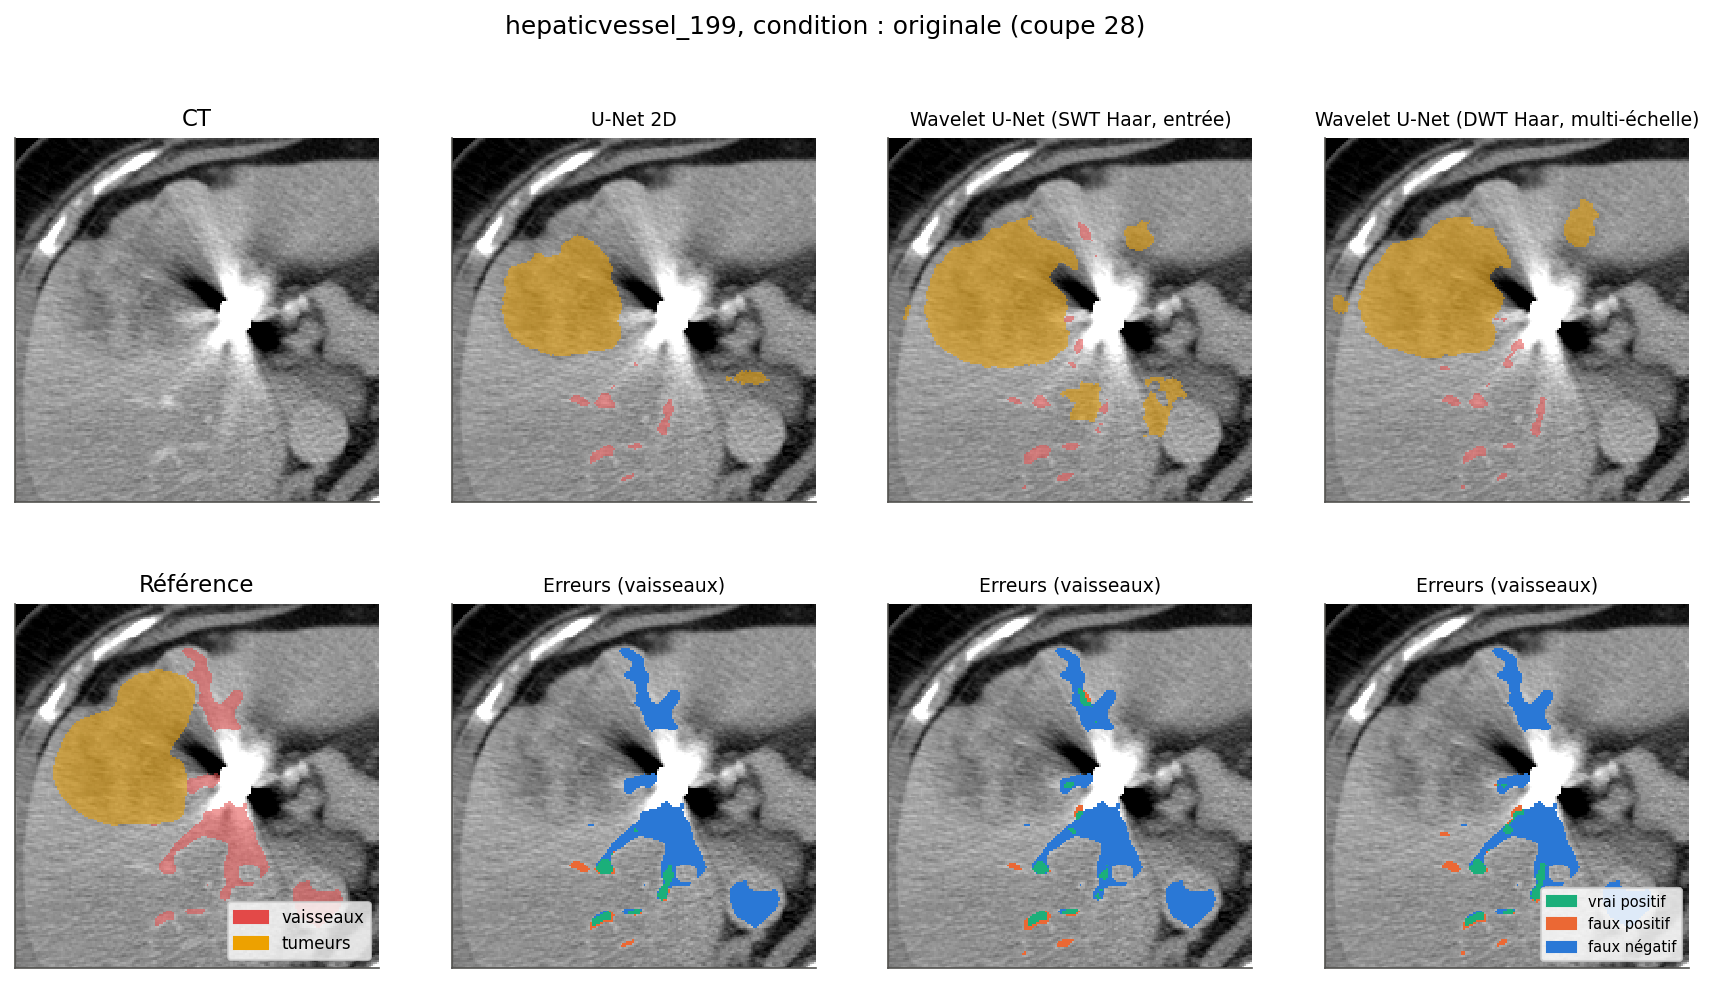

In [15]:
for path in sorted(Path("results/figures/resolution").glob("predictions_*.png")):
    print(path.name); display(Image(str(path)))

Effet des dégradations (rappel : images simulées, pas de vraies acquisitions à une autre résolution) :

- un flou de 1 mm ou un sous-échantillonnage d'un facteur 2 change peu les résultats, et améliore même légèrement certains modèles (le lissage réduit le bruit) ; la variante SWT (seed 0) est la plus sensible au flou (Dice 0,482 contre 0,527) ;
- au facteur 4, le Dice baisse pour tous les modèles 2D (de 1,5 à 12,5 % selon le modèle et la seed) et de 23 % pour le U-Net 3D ; le bruit ajouté au facteur 2 donne les scores les plus bas pour le U-Net et la variante SWT ;
- la perte touche surtout les petits vaisseaux : au facteur 4, le rappel de la ligne centrale pour un rayon inférieur à 1,5 mm tombe à 0,27-0,41, alors qu'il change peu pour les vaisseaux de plus de 3 mm.

L'ordre des modèles en robustesse dépend encore de la seed : avec la seed 0, le U-Net 2D est le plus stable au facteur 4 (- 1,5 % de Dice contre - 9 % pour la variante multi-échelle et - 12,5 % pour la variante SWT) ; avec la seed 1, c'est l'inverse (- 12 % pour le U-Net contre - 3,5 % pour la variante SWT et - 5 % pour la variante multi-échelle). Les ondelettes de Haar ne protègent donc pas de façon systématique les petits vaisseaux quand la résolution baisse. Cela rejoint l'analyse du notebook 02 : les détails de niveau 1 disparaissent presque des images dégradées, si bien que les canaux ondelettes changent de distribution par rapport à l'entraînement.

## 5. Classe tumeur

Les tumeurs ne sont pas l'objet principal de l'étude, mais leurs métriques sont rapportées
séparément pour être complet.

In [16]:
tum = df[(df["class"] == "tumour") & (df["condition"] == "original")]
tum.groupby(["model", "case_id"])[["dice", "recall", "precision", "hd95_mm"]].mean().groupby("model").agg(["mean", "median"]).round(4)

dice          recall         precision           hd95_mm          
                            mean  median    mean  median      mean  median      mean    median
model                                                                                         
unet2d                    0.2597  0.1781  0.3006  0.2344    0.3691  0.2580  125.2166  112.1947
unet3d                    0.1695  0.0813  0.3773  0.3150    0.1754  0.0584  162.9675  166.2494
wavelet_unet_dwt_haar_ms  0.3163  0.2793  0.4582  0.4568    0.3415  0.2259  147.9455  151.1959
wavelet_unet_swt_haar     0.2994  0.2112  0.4694  0.4900    0.2938  0.1378  150.8207  152.8982

Les tumeurs sont mal segmentées par tous les modèles (Dice moyen de 0,17 à 0,33, HD95 supérieur à 100 mm) et certains volumes ont un Dice nul. Les patches de 192 x 192 pixels contiennent rarement une tumeur entière, les tumeurs varient de moins de 1 mL à plus de 2 L, et le modèle a été sélectionné sur le Dice des vaisseaux uniquement. Ce résultat ne doit pas être comparé aux méthodes conçues pour les tumeurs.

## 6. Conclusion

Dans les conditions de ce projet (40 volumes d'entraînement, CPU, deux seeds, 20 volumes de test), je n'ai pas observé d'amélioration robuste de la segmentation des vaisseaux par l'ajout de sous-bandes de Haar, ni en entrée (SWT) ni par injection multi-échelle (DWT) : le sens de la différence de Dice change avec la seed, et la variabilité entre entraînements est du même ordre que les écarts entre modèles. La variante multi-échelle donne en revanche, pour les deux seeds, un HD95 plus faible et moins de faux positifs isolés, ce qui est une piste à vérifier avec davantage d'entraînements. L'étude de la résolution montre que tous les modèles perdent d'abord les vaisseaux de moins de 1,5 mm de rayon, et que les ondelettes n'empêchent pas cette perte. Pour conclure plus solidement, il faudrait au moins 5 seeds par modèle, l'ensemble des 212 volumes d'entraînement et un entraînement sur GPU (notebook 04).